In [ ]:
# 34.  
# Develop an Autoencoder-based anomaly detection model to 
# identify potentially fraudulent credit card transactions using a Credit Card 
# Fraud Detection dataset. Perform the following steps: 
# a. Import Libraries 
# b. Dataset Access: Load the credit card transaction dataset and separate normal 
# transactions from fraudulent transactions using the class label. 
# c. Data Preprocessing: Normalize the transaction features and prepare the 
# training and testing datasets. Use only normal transactions for training the 
# Autoencoder. 
# d. Encoder Implementation: Construct an encoder using Dense layers to 
# compress transaction features into a low-dimensional latent representation. 
# e. Decoder Implementation: Construct a decoder network to reconstruct the 
# original transaction features from the latent representation. 
# f. Model Compilation: Compile the Autoencoder using the Adam optimizer, 
# MSE loss function and suitable evaluation metrics. 
# g. Anomaly Detection: Calculate reconstruction errors for test transactions and 
# classify transactions as normal or fraudulent using a selected threshold. 
# h. Output: Display reconstruction errors, detected fraudulent transactions and 
# model evaluation results. 

In [1]:

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report


In [2]:

# Load dataset
data = pd.read_csv('creditcard.csv')

print(data.head())
print(data['Class'].value_counts())


   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [3]:

# Separate features and labels
X = data.drop('Class', axis=1)
y = data['Class']

# Separate normal and fraudulent transactions
normal = X[y == 0]
fraud = X[y == 1]

# Split normal data for training and testing
X_train, X_normal_test = train_test_split(
    normal, test_size=0.2, random_state=42
)

# Combine normal and fraudulent transactions for testing
X_test = pd.concat([X_normal_test, fraud])

y_test = np.concatenate([
    np.zeros(len(X_normal_test)),
    np.ones(len(fraud))
])

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (227452, 30)
Testing data: (57355, 30)


In [4]:

# Normalize transaction features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data normalized successfully")


Data normalized successfully


In [5]:

# Build Encoder
encoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu')
])


In [6]:

# Build Decoder
decoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(30, activation='linear')
])

# Combine Encoder and Decoder
autoencoder = tf.keras.Sequential([
    encoder,
    decoder
])

autoencoder.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 8)                   │             632 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ (None, 30)                  │             654 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

# Compile model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)


In [8]:

# Train using only normal transactions
history = autoencoder.fit(
    X_train, X_train,
    epochs=10,
    batch_size=256,
    validation_split=0.2,
    verbose=1
)


Epoch 1/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.7728 - mae: 0.5969 - val_loss: 0.6405 - val_mae: 0.5416
Epoch 2/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5840 - mae: 0.5199 - val_loss: 0.5657 - val_mae: 0.5073
Epoch 3/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.5366 - mae: 0.4965 - val_loss: 0.5362 - val_mae: 0.4904
Epoch 4/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5119 - mae: 0.4822 - val_loss: 0.5143 - val_mae: 0.4773
Epoch 5/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.4927 - mae: 0.4699 - val_loss: 0.4993 - val_mae: 0.4668
Epoch 6/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4812 - mae: 0.4612 - val_loss: 0.4906 - val_mae: 0.4596
Epoch 7/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.4739 - mae: 0.4550 - val_loss: 0.4842 - val_mae: 0.4541
Epoch 8/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.4683 - mae: 0.4500 - val_loss: 0.4792 - val_mae: 0.4496
Epoch 9/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - lo

In [9]:

# Reconstruct test transactions
reconstructed = autoencoder.predict(X_test)

# Calculate reconstruction error
errors = np.mean(np.square(X_test - reconstructed), axis=1)

# Calculate training reconstruction errors
train_reconstructed = autoencoder.predict(X_train)
train_errors = np.mean(np.square(X_train - train_reconstructed), axis=1)

# Set threshold
threshold = np.percentile(train_errors, 95)

# Classify transactions
y_pred = (errors > threshold).astype(int)

print("Threshold:", threshold)
print("Detected fraudulent transactions:", np.sum(y_pred))


1793/1793 ━━━━━━━━━━━━━━━━━━━━ 2s 873us/step
7108/7108 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
Threshold: 0.97774876782911
Detected fraudulent transactions: 3306


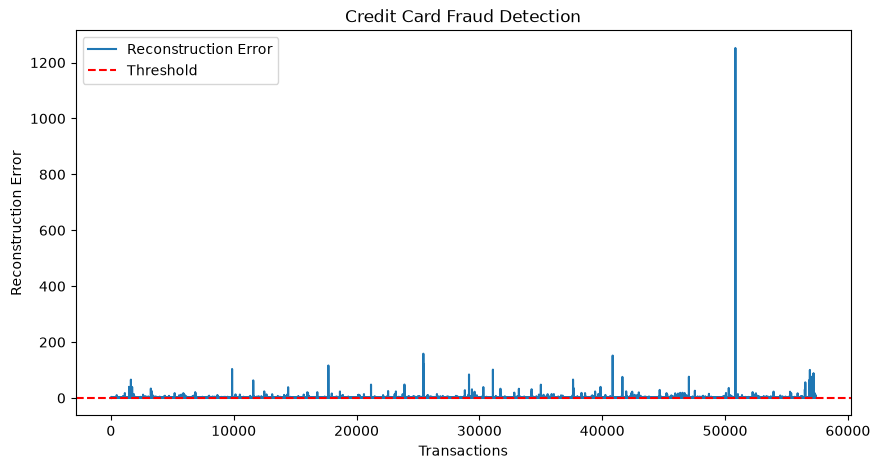

In [10]:

# Plot reconstruction errors
plt.figure(figsize=(10, 5))

plt.plot(errors, label='Reconstruction Error')
plt.axhline(threshold, color='red', linestyle='--', label='Threshold')

plt.xlabel('Transactions')
plt.ylabel('Reconstruction Error')
plt.title('Credit Card Fraud Detection')
plt.legend()
plt.show()


In [11]:

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Normal', 'Fraud']))


Confusion Matrix:
[[53973  2890]
 [   76   416]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     56863
       Fraud       0.13      0.85      0.22       492

    accuracy                           0.95     57355
   macro avg       0.56      0.90      0.60     57355
weighted avg       0.99      0.95      0.97     57355



In [12]:

# Display detected fraudulent transactions
fraud_indices = np.where(y_pred == 1)[0]

print("Total detected frauds:", len(fraud_indices))
print("\nFirst 10 detected transactions:")

for i in fraud_indices[:10]:
    print("Transaction", i, "- Fraudulent")


Total detected frauds: 3306

First 10 detected transactions:
Transaction 43 - Fraudulent
Transaction 50 - Fraudulent
Transaction 53 - Fraudulent
Transaction 59 - Fraudulent
Transaction 74 - Fraudulent
Transaction 87 - Fraudulent
Transaction 106 - Fraudulent
Transaction 117 - Fraudulent
Transaction 119 - Fraudulent
Transaction 167 - Fraudulent
